# DC Exception Copilot - walkthrough

An agentic RAG assistant for warehouse exception handling. This notebook **imports the
project's modules** (the real logic lives in `src/copilot/`, with tests) and walks through
what each build step produces.

| Step | What it builds | Status |
|---|---|---|
| 1 | Download free regulations + GS1 standards | done |
| 2 | Structure-aware chunking with exact citations | done |
| 3 | A synthetic distribution center (database + SOPs + SDS + incidents) | done |
| 4 | Hybrid retrieval (BM25 + vectors) and its evaluation | done |
| 5-10 | Tools, agents, API, evaluation, guardrails, CI | coming |

> Run from the project root after the quickstart in the README. Cells that need an OpenAI key
> fall back to keyword search when no key is configured.

In [1]:
import json
import sqlite3
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd

from copilot.config import DATA_DIR, PROCESSED_DIR, RAW_DIR, settings

pd.set_option("display.max_colwidth", 90)
warnings.filterwarnings("ignore", message="IProgress not found")

# Chart styling: reference palette slots 1-2, recessive axes, text in ink colors
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK_2, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10,
})

## Step 1 - The corpus

Every document is free and public. The download script records a manifest (URL, SHA-256,
size, date) so every answer can be traced back to an exact source version.

In [2]:
manifest = pd.DataFrame(json.loads((RAW_DIR / "manifest.json").read_text(encoding="utf-8")))
manifest["KB"] = (manifest["bytes"] / 1024).round().astype(int)
manifest[["id", "kind", "use", "topic", "KB"]]

,id,kind,use,topic,KB
0,osha_1910_22,ecfr,rag,Walking-working surfaces,2
1,osha_1910_37,ecfr,rag,Exit routes,4
2,osha_1910_106,ecfr,rag,Flammable liquids storage,151
3,osha_1910_157,ecfr,rag,Portable fire extinguishers,14
4,osha_1910_176,ecfr,rag,Materials handling and storage,2
5,osha_1910_178,ecfr,rag,Powered industrial trucks (forklifts),57
6,osha_1910_1200,ecfr,rag,Hazard communication / Safety Data Sheets,355
7,hmr_172_315,ecfr,rag,Limited quantity marking,7
8,hmr_173_150,ecfr,rag,Limited quantities - flammable liquids,11
9,hmr_173_306,ecfr,rag,Aerosols and compressed gases - limited quantities,45


## Step 2 - Structure-aware chunks

Regulations are split on their lettered paragraphs, PDFs on their table of contents, the
DC's own docs on their sections - so every chunk carries a precise citation.

In [3]:
from copilot.retrieval.retriever import load_chunks

chunks = load_chunks(PROCESSED_DIR / "chunks.jsonl")
naive = load_chunks(PROCESSED_DIR / "chunks_naive.jsonl")
names = {"osha": "OSHA regulations", "hmr": "Hazmat regulations", "gs1": "GS1 standards",
         "dc_sops": "DC SOPs", "dc_sds": "DC safety data sheets", "dc_incidents": "DC incident reports"}
group = lambda c: names[c.get("extra", {}).get("collection") or c["source_id"].split("_")[0]]
pd.Series(Counter(group(c) for c in chunks), name="chunks").to_frame()

,chunks
OSHA regulations,350
Hazmat regulations,74
GS1 standards,1201
DC SOPs,23
DC safety data sheets,32
DC incident reports,205


**One chunk, as the LLM will see it** - note the exact citation and breadcrumb:

In [4]:
example = next(c for c in chunks if c["citation"] == "29 CFR 1910.178(l)")
print(example["citation"], "->", example["url"], "\n")
print(example["text"][:900], "...")

29 CFR 1910.178(l) -> https://www.ecfr.gov/current/title-29/section-1910.178 

29 CFR 1910.178 Powered industrial trucks
29 CFR 1910.178(l) - Powered industrial trucks > (l) Operator training.

(l) Operator training. (1) Safe operation. (i) The employer shall ensure that each powered industrial truck operator is competent to operate a powered industrial truck safely, as demonstrated by the successful completion of the training and evaluation specified in this paragraph (l).

(ii) Prior to permitting an employee to operate a powered industrial truck (except for training purposes), the employer shall ensure that each operator has successfully completed the training required by this paragraph (l), except as permitted by paragraph (l)(5).

(2) Training program implementation. (i) Trainees may operate a powered industrial truck only:

(A) Under the direct supervision of persons who have the knowledge, training, and experience to train operators and evaluate their compet ...


**Same rule in the naive LangChain chunks** - a fixed character window with no idea where a rule starts or ends:

In [5]:
naive_example = next(c for c in naive if "conducted at least once every three years" in c["text"])
print(naive_example["citation"], "\n")
print(naive_example["text"][:600], "...")

osha_1910_178 (chunk 14) 

(C) The operator has received an evaluation that reveals that the operator is not operating the truck safely;
(D) The operator is assigned to drive a different type of truck; or
(E) A condition in the workplace changes in a manner that could affect safe operation of the truck.
(iii) An evaluation of each powered industrial truck operator's performance shall be conducted at least once every three years.
(5) Avoidance of duplicative training. If an operator has previously received training in a topic specified in paragraph (l)(3) of this section, and such training is appropriate to the truck and ...


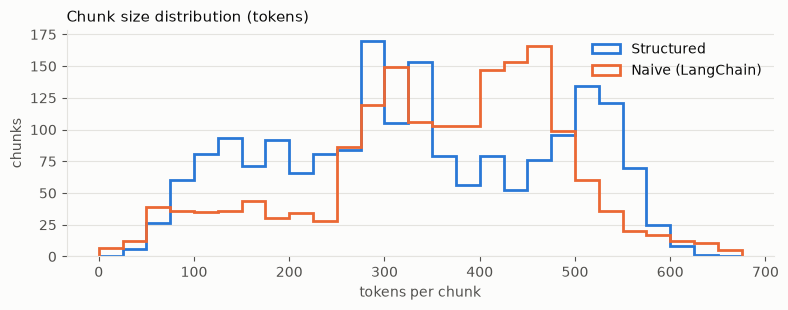

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.2))
bins = range(0, 700, 25)
ax.hist([c["tokens"] for c in chunks], bins=bins, histtype="step", color=BLUE, linewidth=2,
        label="Structured")
ax.hist([c["tokens"] for c in naive], bins=bins, histtype="step", color=ORANGE, linewidth=2,
        label="Naive (LangChain)")
ax.set_title("Chunk size distribution (tokens)", loc="left", fontsize=11, color=INK)
ax.set_xlabel("tokens per chunk"); ax.set_ylabel("chunks")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## Step 3 - The synthetic distribution center

*Meridian Consumer Goods - Columbus DC* is fictional, but its hazmat classifications come
from the real 49 CFR 172.101 table. The SQLite database is what the agent's SQL tool will query.

In [7]:
con = sqlite3.connect(DATA_DIR / "dc.db")
q = lambda sql: pd.read_sql_query(sql, con)
tables = [r[0] for r in con.execute("SELECT name FROM sqlite_master WHERE type='table'")]
pd.DataFrame({"table": tables,
              "rows": [con.execute(f'SELECT COUNT(*) FROM "{t}"').fetchone()[0] for t in tables]})

,table,rows
0,zones,8
1,locations,1540
2,skus,43
3,suppliers,7
4,carriers,5
5,customers,7
6,employees,10
7,inventory,561
8,inbound_receipts,408
9,receipt_lines,960


**Exceptions by type and severity** - the history the agent can learn from:

In [8]:
q("SELECT type, severity, COUNT(*) AS n FROM exceptions GROUP BY 1, 2").pivot_table(
    index="type", columns="severity", values="n", fill_value=0)[["high", "medium", "low"]].astype(int)

severity,high,medium,low
type,,,
DAMAGED_INBOUND,0,13,19
FORKLIFT_NEAR_MISS,2,11,0
HAZMAT_SEGREGATION,7,0,0
INVENTORY_MISMATCH,0,0,34
LATE_CARRIER,33,43,0
LEAK_SPILL,9,3,0
MISSING_HAZMAT_MARKING,0,12,0
MISSING_SSCC,0,44,62
QTY_DISCREPANCY,0,0,20


**A planted scenario:** tomorrow's 06:00 trailer to ProClean. Hydrogen peroxide (class 5.1) and
caustic stripper (class 8) are both fully regulated - a 49 CFR 177.848 "O" pair. The drain opener
is a limited quantity, so it does not count. The agent should catch this.

In [9]:
q("""
SELECT s.shipment_id, s.planned_departure, c.name AS customer, k.sku, k.description,
       k.un_number, k.hazard_class,
       CASE k.limited_quantity WHEN 1 THEN 'yes' ELSE 'no' END AS limited_qty
FROM shipments s
JOIN customers c USING (customer_id)
JOIN shipment_lines l USING (shipment_id)
JOIN skus k USING (sku)
WHERE s.shipment_id = 'SHP-01209'
""")

,shipment_id,planned_departure,customer,sku,description,un_number,hazard_class,limited_qty
0,SHP-01209,2026-10-17 06:00,ProClean Janitorial Supply,HPOX-001,CleanPro Hydrogen Peroxide 35% Stabilized 20 L drum,UN2014,5.1,no
1,SHP-01209,2026-10-17 06:00,ProClean Janitorial Supply,CAUS-001,CleanPro Caustic Floor Stripper Heavy Duty 20 L drum,UN1824,8,no
2,SHP-01209,2026-10-17 06:00,ProClean Janitorial Supply,DRNO-001,CleanPro Drain Opener Gel Max Gel 1 L,UN1824,8,yes


## Step 4 - Hybrid retrieval

BM25 keyword search catches exact codes; vector search catches paraphrases; Reciprocal Rank
Fusion combines both. Without an API key these cells use keyword search only.

In [10]:
from copilot.retrieval.retriever import Retriever

embedder = None
if settings.openai_api_key:
    from copilot.retrieval.embeddings import openai_embedder
    embedder = openai_embedder()
retriever = Retriever(chunks, embedder)
MODE = "hybrid" if embedder else "bm25"

def show(question, k=4, **filters):
    hits = retriever.search(question, k=k, mode=MODE, where=filters or None)
    print(f"Q: {question}   [{MODE}]")
    return pd.DataFrame([{"rank": i, "citation": h.chunk["citation"],
                          "snippet": h.chunk["body"][:110].replace("\n", " ")}
                         for i, h in enumerate(hits, 1)])

show("Can pool shock and chlorine tablets go on the same truck?")

Q: Can pool shock and chlorine tablets go on the same truck?   [hybrid]


,rank,citation,snippet
0,1,SOP-HAZ-002 §3,## 3. Key rule: 49 CFR 177.848 segregation table The segregation table in 49 CFR 177.8...
1,2,SDS-TCCA §8-16,"## 8. Exposure controls / personal protection Goggles, rubber gloves, dust respirator...."
2,3,SDS-TCCA §1-7,## 1. Identification - **Product:** AquaShock Chlorine Tablets (TCCA) (20 kg pail) - *...
3,4,SDS-PSHB §7-16,## 7. Handling and storage Handle in accordance with good industrial hygiene. At DC-CO...


In [11]:
show("What protective gear do I need to clean up a drain opener spill?", doc_type="sds")

Q: What protective gear do I need to clean up a drain opener spill?   [hybrid]


,rank,citation,snippet
0,1,SDS-DRNO §1-10,## 1. Identification - **Product:** CleanPro Drain Opener Gel (1 L) - **Product family...
1,2,SDS-DRNO §11-16,"## 11. Toxicological information Corrosive: severe burns to skin, eyes and digestive t..."
2,3,SDS-LQD §1-10,"## 1. Identification - **Product:** Brightwash Liquid Laundry Detergent (1.47 L, 2.95 ..."
3,4,SDS-PSHB §1-6,## 1. Identification - **Product:** AquaShock Pool Shock Bulk Pail (25 kg pail) - **Pr...


### Retrieval evaluation

42 golden questions, phrased the way DC staff would ask them. A hit means a chunk containing the
known evidence phrase is in the top 5. Re-run `python -m copilot.eval.retrieval_eval` to refresh.

In [12]:
results = pd.DataFrame(json.loads((DATA_DIR / "eval" / "results" / "retrieval.json").read_text()))
results[["strategy", "mode", "hit@1", "hit@5", "mrr@10"]].style.format(
    {"hit@1": "{:.0%}", "hit@5": "{:.0%}", "mrr@10": "{:.3f}"}).hide(axis="index")

strategy,mode,hit@1,hit@5,mrr@10
structured,bm25,38%,69%,0.520
structured,vector,64%,88%,0.731
structured,hybrid,62%,81%,0.697
naive,bm25,43%,69%,0.562
naive,vector,60%,81%,0.671
naive,hybrid,60%,86%,0.700


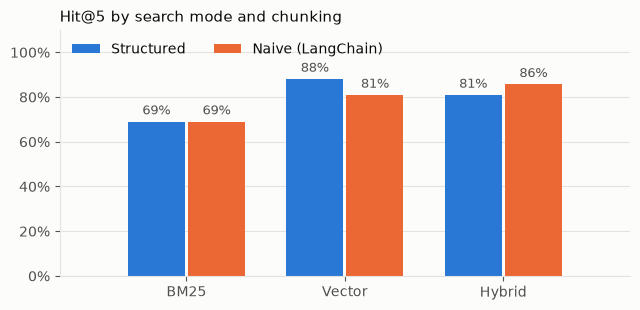

In [13]:
pivot = results.pivot(index="mode", columns="strategy", values="hit@5")
pivot = pivot.loc[[m for m in ["bm25", "vector", "hybrid"] if m in pivot.index]]
fig, ax = plt.subplots(figsize=(6.5, 3.2))
x = list(range(len(pivot)))
w = 0.36
for off, col, color, label in [(-w / 2 - 0.01, "structured", BLUE, "Structured"),
                               (w / 2 + 0.01, "naive", ORANGE, "Naive (LangChain)")]:
    bars = ax.bar([i + off for i in x], pivot[col], width=w, color=color, label=label)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in pivot[col]], padding=3, color=INK_2, fontsize=9)
ax.set_xticks(x, ["BM25" if m == "bm25" else m.capitalize() for m in pivot.index])
ax.set_xlim(-0.8, len(x) - 0.2); ax.set_ylim(0, 1.1); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Hit@5 by search mode and chunking", loc="left", fontsize=11, color=INK)
ax.legend(frameon=False, loc="upper left", ncols=2)
plt.tight_layout(); plt.show()

## What's next

Step 5 adds the deterministic tools the agent can call (read-only SQL, Hazardous Materials Table
lookup, 177.848 segregation checker); step 6 wires them into a LangGraph agent with cited answers
and a human-approval step. This notebook will grow a section for each.